# M5 Forecasting — Part 1 · Statistical models
## Notebook 00 · Data understanding (a short first-look EDA)

**Owner:** Calvin (Statistical part: EDA + ARIMA / SARIMA)
**Data:** [Kaggle — M5 Forecasting Accuracy](https://www.kaggle.com/competitions/m5-forecasting-accuracy/data) (Walmart unit sales, 2011-01-29 → 2016-05-22)

---

### Where this notebook sits in the project

| # | Part | Owner(s) | Uses the statistical part how? |
|---|------|----------|-------------------------------|
| 1 | **Statistical (EDA, ARIMA, SARIMA)** | Huijie, Ruihang | Baseline + interpretable structure (trend, weekly / yearly seasonality) |
| 2 | Machine learning (×2) | Bertille, Romain | Can consume SARIMA forecasts / fitted components as **features** |
| 3 | Deep learning | Bhavini | Same; or as a benchmark the DL model must beat |
| 4 | Frontier models | Kabilan | Benchmark |
| 5 | Competition-winner analysis | Claude | Explains why LightGBM won M5 |

### Plan for the statistical part (skeleton first, details later)

1. **00 — Data understanding** *(this notebook)*: what is in each file, how the files connect, how sparse the data is.
2. **01 — Full EDA**: trend, seasonality (weekly / yearly), calendar effects (events, SNAP), prices, decomposition.
3. **02 — Stationarity & identification**: ADF / KPSS tests, differencing, ACF / PACF → candidate orders.
4. **03 — ARIMA & SARIMA**: fit on aggregate series, residual diagnostics (Ljung–Box), 28-day forecast, compare with naive / seasonal-naive baselines.
5. **04 — Hand-off**: export SARIMA forecasts / components as features for the ML & DL teams.

This notebook only answers one question: **"What exactly are we looking at?"**

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = Path("m5-forecasting-accuracy")   # folder next to this notebook

# ---- one consistent look for every chart in the project ----
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3 (fixed order)
GREY, INK, INK2 = "#9a9893", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (12, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.grid": True,
    "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 1.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 30)

## 1 · The five files — what each one is

Think of the dataset as **one big spreadsheet of sales + two lookup tables**:

| File | Plain-English meaning | Shape | Key to join on |
|------|----------------------|-------|----------------|
| `sales_train_evaluation.csv` → `df_sales_wide` | **The core.** One row per *product in a store*; one column per *day* (`d_1 … d_1941`), each cell = **units sold** that day | 30,490 × 1,947 | `id`, `item_id`, `store_id` |
| `sales_train_validation.csv` | Same thing but stops 28 days earlier (`d_1 … d_1913`). An older release — **we don't need it** | 30,490 × 1,919 | — |
| `calendar.csv` → `df_calendar` | A dictionary that turns `d_123` into a real date, plus weekday, events (holidays), and SNAP flags | 1,969 × 14 | `d`, `wm_yr_wk` |
| `sell_prices.csv` → `df_prices` | Weekly price of each product in each store | 6.8 M × 4 | `store_id`, `item_id`, `wm_yr_wk` |
| `sample_submission.csv` | The answer sheet format for Kaggle: 28 future days (`F1 … F28`) per series | 60,980 × 29 | `id` |

> **Decision:** we use `sales_train_evaluation.csv` because it contains *everything* in the validation file **plus** 28 more days of known answers (d_1914–d_1941). Those last 28 days become **our own test set**.

In [2]:
# Sales are small integers -> store them as int16 to save ~75% memory
head = pd.read_csv(DATA_DIR / "sales_train_evaluation.csv", nrows=0).columns
d_cols = [c for c in head if c.startswith("d_")]
df_sales_wide = pd.read_csv(DATA_DIR / "sales_train_evaluation.csv",
                    dtype={c: "int16" for c in d_cols})
df_calendar = pd.read_csv(DATA_DIR / "calendar.csv", parse_dates=["date"])
df_prices = pd.read_csv(DATA_DIR / "sell_prices.csv",
                     dtype={"store_id": "category", "item_id": "category", "wm_yr_wk": "int16", "sell_price": "float32"})

for name, df in [("df_sales_wide", df_sales_wide), ("df_calendar", df_calendar), ("df_prices", df_prices)]:
    print(f"{name:14s} shape={df.shape}   memory={df.memory_usage(deep=True).sum()/1e6:,.0f} MB")
df_sales_wide.iloc[:3, :10]

df_sales_wide  shape=(30490, 1947)   memory=131 MB
df_calendar    shape=(1969, 14)   memory=1 MB
df_prices      shape=(6841121, 4)   memory=62 MB


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


### 1.1 · How to read one `id`

`FOODS_3_090_CA_3_evaluation` = **category** `FOODS` → **department** `FOODS_3` → **item** `FOODS_3_090` → sold in **store** `CA_3` (state `CA`). The suffix `_evaluation` just tells you which file it came from.

So **each row is one time series**: "how many units of this product did this store sell, every day for 5.3 years".

In [3]:
id_cols = ["item_id", "dept_id", "cat_id", "store_id", "state_id"]
print(df_sales_wide[id_cols].nunique().to_string())
print()
print(pd.crosstab(df_sales_wide["cat_id"], df_sales_wide["state_id"], margins=True))

item_id     3049
dept_id        7
cat_id         3
store_id      10
state_id       3

state_id      CA    TX    WI    All
cat_id                             
FOODS       5748  4311  4311  14370
HOBBIES     2260  1695  1695   5650
HOUSEHOLD   4188  3141  3141  10470
All        12196  9147  9147  30490


### 1.2 · The timeline

`calendar.csv` covers 1,969 days, but sales are only known for the first 1,941.

In [4]:
df_calendar_by_d = df_calendar.set_index("d")
periods = pd.DataFrame({
    "days": ["d_1 – d_1913", "d_1914 – d_1941", "d_1942 – d_1969"],
    "from": [df_calendar_by_d.loc["d_1", "date"], df_calendar_by_d.loc["d_1914", "date"], df_calendar_by_d.loc["d_1942", "date"]],
    "to":   [df_calendar_by_d.loc["d_1913", "date"], df_calendar_by_d.loc["d_1941", "date"], df_calendar_by_d.loc["d_1969", "date"]],
    "role in Kaggle": ["training", "public leaderboard (answers released later)", "private leaderboard (answers never public)"],
    "role in OUR project": ["model fitting", "TEST SET (28-day horizon)", "not usable — no ground truth"],
}, index=["train", "validation", "evaluation"])
periods

,days,from,to,role in Kaggle,role in OUR project
train,d_1 – d_1913,2011-01-29,2016-04-24,training,model fitting
validation,d_1914 – d_1941,2016-04-25,2016-05-22,public leaderboard (answers released later),TEST SET (28-day horizon)
evaluation,d_1942 – d_1969,2016-05-23,2016-06-19,private leaderboard (answers never public),not usable — no ground truth


## 2 · The hierarchy — why 30,490 rows become 42,840 series

Sales can be **added up** along the product tree (item → dept → category → total) and the geography tree (store → state → total). The M5 competition scores forecasts at **12 aggregation levels**:

In [5]:
levels = [
    ("1  Total", []), ("2  State", ["state_id"]), ("3  Store", ["store_id"]),
    ("4  Category", ["cat_id"]), ("5  Department", ["dept_id"]),
    ("6  State × Category", ["state_id", "cat_id"]), ("7  State × Department", ["state_id", "dept_id"]),
    ("8  Store × Category", ["store_id", "cat_id"]), ("9  Store × Department", ["store_id", "dept_id"]),
    ("10 Item", ["item_id"]), ("11 Item × State", ["item_id", "state_id"]), ("12 Item × Store", ["item_id", "store_id"]),
]
X = df_sales_wide[d_cols].to_numpy()
rows = []
for name, keys in levels:
    if keys:
        agg = df_sales_wide.groupby(keys)[d_cols].sum().to_numpy()
    else:
        agg = X.sum(axis=0, keepdims=True)
    rows.append({"level": name, "n_series": agg.shape[0],
                 "avg units / day / series": agg.mean().round(1),
                 "% of days with 0 df_sales_wide": (agg == 0).mean() * 100})
hier = pd.DataFrame(rows).set_index("level")
print("Total series across the 12 levels:", hier["n_series"].sum())
hier.round(1)

Total series across the 12 levels: 42840


,n_series,avg units / day / series,% of days with 0 df_sales_wide
level,,,
1 Total,1,34480.8,0.0
2 State,3,11493.6,0.0
3 Store,10,3448.1,0.1
4 Category,3,11493.6,0.2
5 Department,7,4925.8,0.2
6 State × Category,9,3831.2,0.2
7 State × Department,21,1641.9,0.2
8 Store × Category,30,1149.4,0.2
9 Store × Department,70,492.6,0.3


**How to read this table — the single most important fact for ARIMA/SARIMA:**

- At the **bottom** (level 12: one product in one store) about **68 % of all days are zeros**. Such a series looks like `0 0 1 0 0 0 2 0 …` — this is called **intermittent demand**. ARIMA assumes a continuous, roughly bell-shaped signal, so it fits these badly (it predicts 0.3 units, or negative units).
- At the **top** (levels 1–9) zeros practically disappear (the few remaining are Christmas closures). The series are smooth, trended and seasonal — **exactly what ARIMA/SARIMA were designed for.**

⇒ This is the data-driven argument for running ARIMA / SARIMA on **aggregate levels** (total, state, store, category…), not on 30,490 individual items.

## 3 · Data quality: missing values and "fake" zeros

In [6]:
print("Missing values in df_sales_wide:", int(df_sales_wide[d_cols].isna().sum().sum()))
print("Missing values in df_calendar:\n", df_calendar.isna().sum()[lambda s: s > 0].to_string())

Missing values in df_sales_wide: 0
Missing values in df_calendar:
 event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964


- **Sales:** no missing values at all.
- **Calendar:** the `event_*` columns are mostly empty — that's normal, empty simply means "no holiday that day". Only 5 days have a *second* event.

But there is a hidden quality issue: **not every zero means "nobody bought it"**. Many products simply were not on the shelf yet. Look at how many zeros sit *before the first ever sale* of a product:

In [7]:
first_sale = (X > 0).argmax(axis=1)                     # index of first non-zero day per series
leading_zeros = first_sale.sum()
print(f"Total zero cells:               {(X == 0).sum():>12,}")
print(f"Zeros before the first sale:    {leading_zeros:>12,}  ({leading_zeros / (X == 0).sum():.0%} of all zeros)")
print(f"Median launch day of a product: d_{int(np.median(first_sale)) + 1}")

# prices confirm it: a price row only exists once the item is on sale
first_price_wk = df_prices.groupby(["store_id", "item_id"])["wm_yr_wk"].min()
print(f"\nItems with a price from the very first week: {(first_price_wk == df_calendar.wm_yr_wk.min()).mean():.0%}")

Total zero cells:                 40,241,819


Zeros before the first sale:      12,384,870  (31% of all zeros)
Median launch day of a product: d_160



Items with a price from the very first week: 36%


**Takeaway:** roughly a third of all zeros are "product not launched yet", not "zero demand". For aggregate ARIMA this inflates the **upward trend** in early years (more products → more sales), which is worth one sentence in the report. For the ML team, it means these leading zeros should probably be **dropped** from training rows.

## 4 · The top-level picture: total daily sales

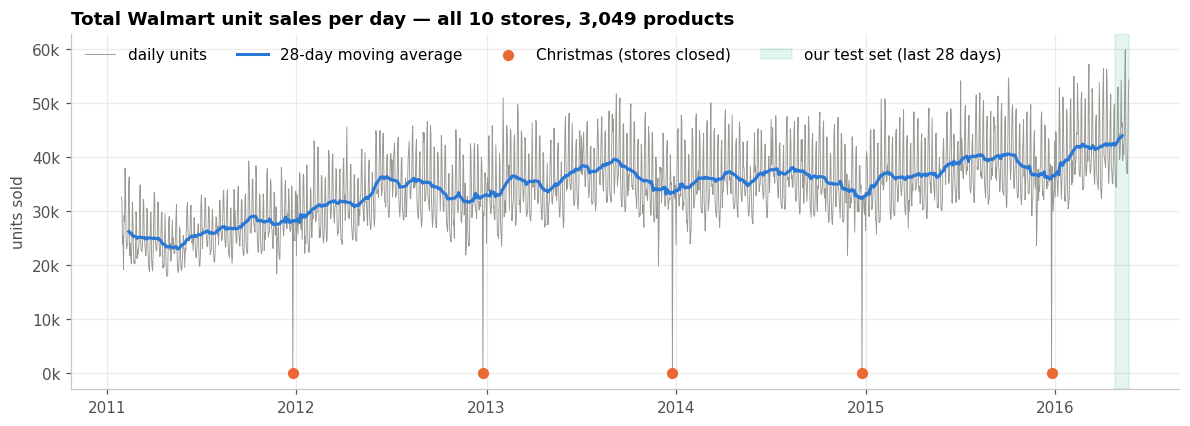

Average units/day by year:
2011    26281.0
2012    32956.0
2013    35988.0
2014    35862.0
2015    37810.0
2016    41835.0


In [8]:
dates = df_calendar["date"].iloc[:len(d_cols)].to_numpy()
ts_total = pd.Series(X.sum(axis=0), index=pd.DatetimeIndex(dates), name="units")

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(ts_total.index, ts_total, color=GREY, lw=0.6, label="daily units")
ax.plot(ts_total.index, ts_total.rolling(28, center=True).mean(), color=BLUE, lw=2, label="28-day moving average")
xmas = ts_total[ts_total < 1000]
ax.scatter(xmas.index, xmas, color=ORANGE, s=40, zorder=3, label="Christmas (stores closed)")
ax.axvspan(dates[1913], dates[-1], color=AQUA, alpha=0.12, label="our test set (last 28 days)")
ax.set_title("Total Walmart unit sales per day — all 10 stores, 3,049 products")
ax.set_ylabel("units sold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
ax.legend(loc="upper left", ncol=4)
plt.show()

print("Average units/day by year:")
print(ts_total.groupby(ts_total.index.year).mean().round(0).to_string())

**What we see**

1. **Trend** — clear upward drift (≈ 26k units/day in 2011 → ≈ 42k in 2016). Partly real growth, partly more products being listed (section 3).
2. **Christmas** — sales fall to almost 0 every 25 December (the only closed day). These 5 points are **outliers** for ARIMA and must be handled (impute or dummy variable).
3. **Weekly "saw-tooth"** — the grey band is thick because sales go up and down every week. Zoom in below.
4. **Yearly wave** — a gentle swell: weaker in January, stronger in summer.

## 5 · Seasonality in two zooms: the week and the year

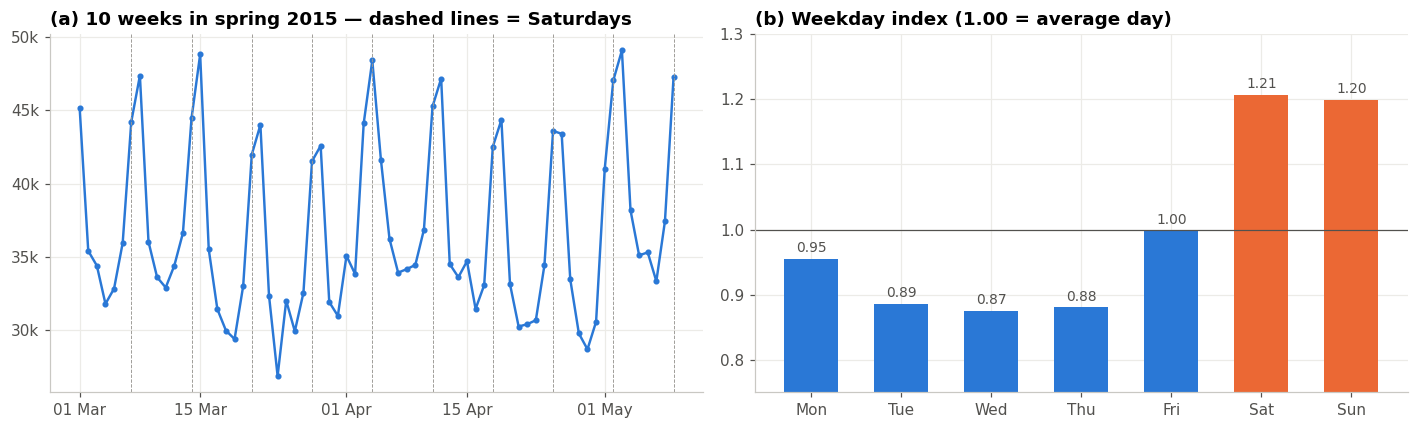

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# (a) a 10-week window
win = ts_total["2015-03-01":"2015-05-09"]
axes[0].plot(win.index, win, color=BLUE, marker="o", ms=3)
for d in win.index[win.index.dayofweek == 5]:
    axes[0].axvline(d, color=GREY, lw=0.6, ls="--")
axes[0].set_title("(a) 10 weeks in spring 2015 — dashed lines = Saturdays")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))

# (b) average weekday index
no_xmas = ts_total[ts_total > 1000]
wd = no_xmas.groupby(no_xmas.index.dayofweek).mean()
wd = wd / wd.mean()
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
cols = [ORANGE if i >= 5 else BLUE for i in range(7)]
axes[1].bar(names, wd.values, color=cols, width=0.6)
axes[1].axhline(1, color=INK2, lw=0.8)
for i, v in enumerate(wd.values):
    axes[1].text(i, v + 0.01, f"{v:.2f}", ha="center", color=INK2, fontsize=9)
axes[1].set_ylim(0.75, 1.3)
axes[1].set_title("(b) Weekday index (1.00 = average day)")
plt.tight_layout(); plt.show()

**Weekly seasonality is strong**: Saturday and Sunday sell ~20 % above an average day; Tue–Thu ~12 % below. The pattern repeats every **7 days** → this is the `s = 7` in **SARIMA(p,d,q)(P,D,Q)₇**.

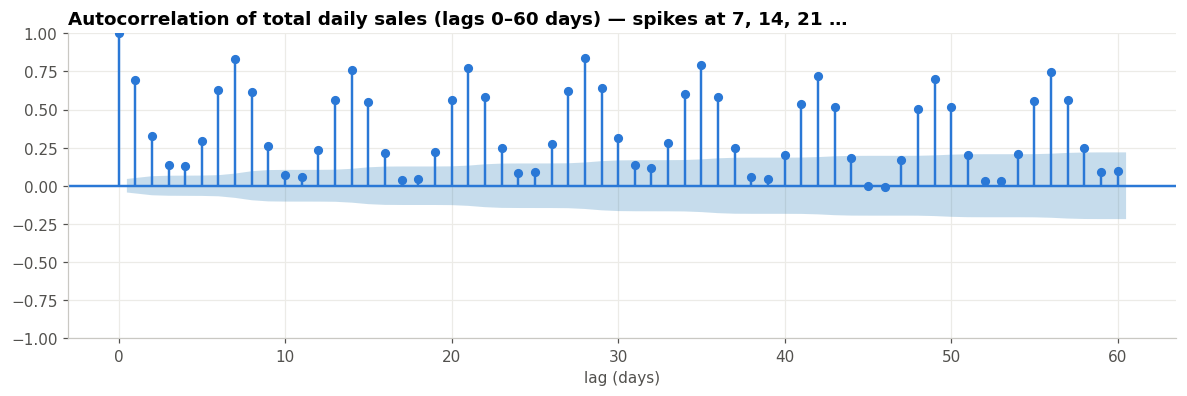

In [10]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(13, 3.6))
plot_acf(ts_total.clip(lower=ts_total.median() * 0.3), lags=60, ax=ax, color=BLUE,
         vlines_kwargs={"colors": BLUE}, title="")
ax.set_title("Autocorrelation of total daily sales (lags 0–60 days) — spikes at 7, 14, 21 …")
ax.set_xlabel("lag (days)")
plt.show()

**Reading the ACF (autocorrelation function):** each bar answers *"how similar is today to the day k days ago?"*. Bars at 7, 14, 21, 28… stand above their neighbours → the weekly cycle. The bars also decay **very slowly** → the series is **not stationary** (it has a trend). Both facts point toward **differencing** (`d = 1`) and **seasonal differencing** (`D = 1, s = 7`) — to be tested formally (ADF / KPSS) in notebook 02.

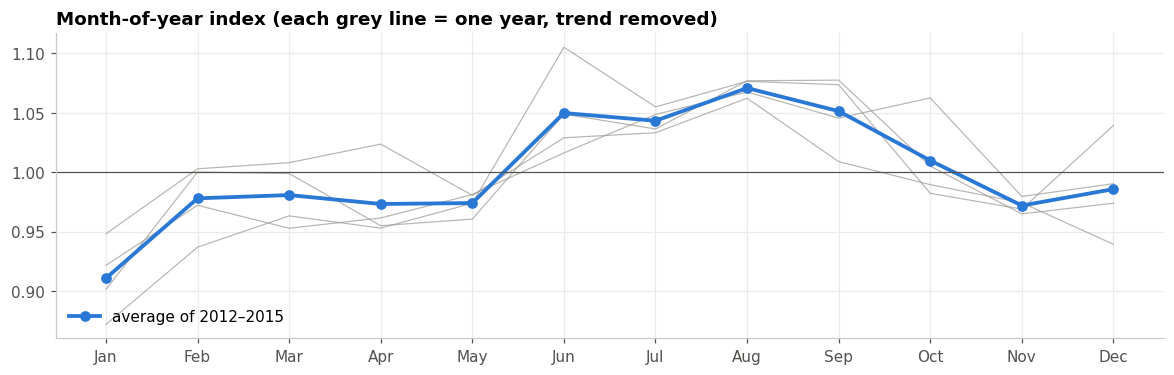

In [11]:
full_years = no_xmas["2012":"2015"]           # 2011 and 2016 are incomplete years
monthly = full_years.groupby([full_years.index.year, full_years.index.month]).mean().unstack(0)
monthly = monthly / monthly.mean()          # index each year to its own average -> removes trend
fig, ax = plt.subplots(figsize=(13, 3.6))
for yr in monthly.columns:
    ax.plot(monthly.index, monthly[yr], color=GREY, lw=0.8, alpha=0.7)
ax.plot(monthly.index, monthly.mean(axis=1), color=BLUE, lw=2.5, marker="o", label="average of 2012–2015")
ax.axhline(1, color=INK2, lw=0.8)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Month-of-year index (each grey line = one year, trend removed)")
ax.legend(loc="lower left"); plt.show()

**Yearly seasonality is mild** compared with the weekly one: January is clearly the weakest month (≈ −9 %), summer (Jun–Sep) the strongest (≈ +4 to +7 %), and the grey lines show the shape is not identical every year. Important modelling consequence: a SARIMA with **s = 365** is computationally impractical (it would need to estimate lags 365, 730…). The usual workaround — to explore in notebook 03 — is **SARIMA with s = 7 + Fourier terms (sin/cos) for the yearly cycle** as external regressors (that's SARIMAX).

## 6 · Who sells what: states and categories

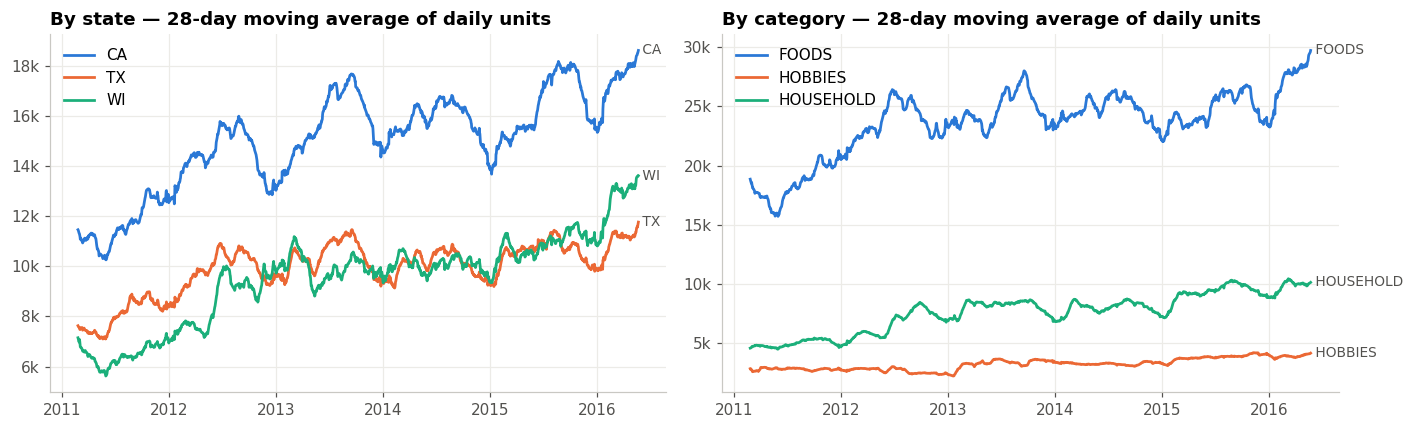

Share of all units sold: {'FOODS': 0.686, 'HOBBIES': 0.093, 'HOUSEHOLD': 0.221}


In [12]:
def rolling_by(col):
    g = df_sales_wide.groupby(col)[d_cols].sum().T
    g.index = pd.DatetimeIndex(dates)
    return g.rolling(28).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, col, title in [(axes[0], "state_id", "By state"), (axes[1], "cat_id", "By category")]:
    g = rolling_by(col)
    for c, color in zip(g.columns, [BLUE, ORANGE, AQUA]):
        ax.plot(g.index, g[c], color=color, lw=1.8, label=c)
        ax.text(g.index[-1], g[c].iloc[-1], f" {c}", color=INK2, va="center", fontsize=9)
    ax.set_title(f"{title} — 28-day moving average of daily units")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
    ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

share = df_sales_wide.groupby("cat_id")[d_cols].sum().sum(axis=1)
print("Share of all units sold:", (share / share.sum()).round(3).to_dict())

- **California** sells the most (it has 4 stores vs 3 for TX and WI). **Wisconsin** overtakes Texas in 2016.
- **FOODS** ≈ 69 % of all units, **HOUSEHOLD** ≈ 22 %, **HOBBIES** ≈ 9 %. Any model on the *total* is therefore mostly a model of food sales.
- Each line has its own trend and level shifts (e.g. WI jumps in 2012) → a single model for all of them would be wrong; each aggregate series needs its own ARIMA fit.

## 7 · The two lookup tables at a glance

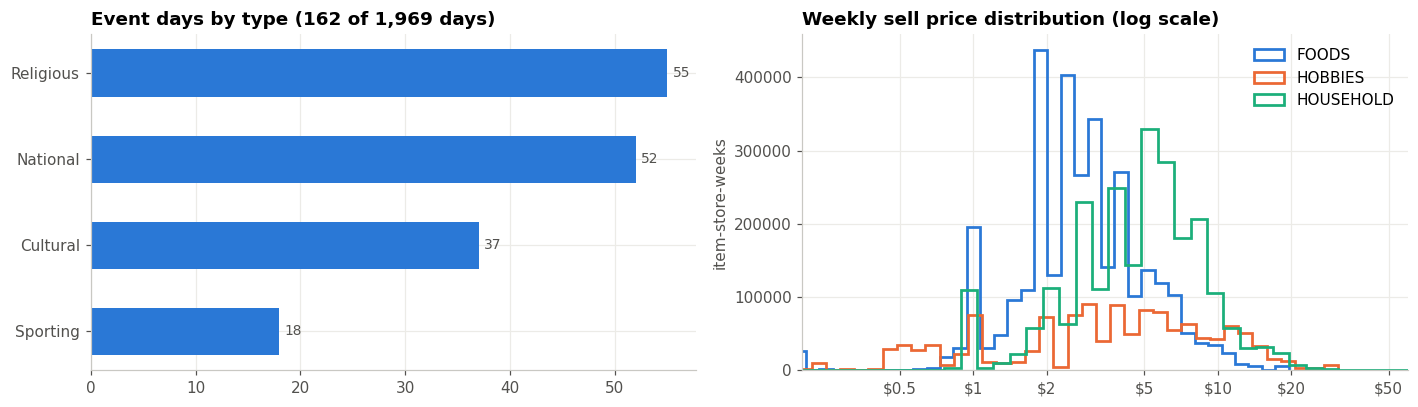

SNAP days per state: {'snap_CA': 650, 'snap_TX': 650, 'snap_WI': 650}


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

ev = df_calendar["event_type_1"].value_counts()
axes[0].barh(ev.index, ev.values, color=BLUE, height=0.55)
for i, v in enumerate(ev.values):
    axes[0].text(v + 0.5, i, str(v), va="center", color=INK2, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_title(f"Event days by type ({df_calendar['event_type_1'].notna().sum()} of 1,969 days)")

p = df_prices.assign(cat_id=df_prices["item_id"].astype(str).str.split("_").str[0])
for c, color in zip(["FOODS", "HOBBIES", "HOUSEHOLD"], [BLUE, ORANGE, AQUA]):
    axes[1].hist(np.log10(p.loc[p.cat_id == c, "sell_price"]), bins=60, histtype="step", lw=1.8, color=color, label=c)
axes[1].set_xticks(np.log10([0.5, 1, 2, 5, 10, 20, 50]))
axes[1].set_xticklabels(["$0.5", "$1", "$2", "$5", "$10", "$20", "$50"])
axes[1].set_xlim(np.log10(0.2), np.log10(60))
axes[1].set_ylabel("item-store-weeks")
axes[1].set_title("Weekly sell price distribution (log scale)")
axes[1].legend()
plt.tight_layout(); plt.show()

print("SNAP days per state:", df_calendar[["snap_CA", "snap_TX", "snap_WI"]].sum().to_dict())

- **Events:** 162 event days (≈ 8 %): religious, national, cultural, sporting. They are candidate **exogenous regressors** (the "X" in SARIMAX).
- **SNAP** (US food-stamp program): each state has exactly 650 SNAP days, always 10 days in the first half of each month — and they are *different days per state*. That is why SNAP effects must be modelled at **state level**, not on the total.
- **Prices:** FOODS are cheap (~$1–5), HOUSEHOLD a bit more expensive, HOBBIES widest. Prices are **weekly** and per item, so they matter much more for the item-level ML models than for our aggregate ARIMA.

## 8 · Summary — what this means for each part of the project

| Finding | Evidence | Consequence for **ARIMA / SARIMA** | Consequence for **ML / DL teammates** |
|---|---|---|---|
| 68 % zeros at item-store level, ~0 % at aggregate levels | Section 2 table | Model **aggregate** series (total, state, store, category) | Need models that handle zeros (Tweedie / Poisson loss in LightGBM) |
| ~⅓ of zeros are "not launched yet" | Section 3 | Explains part of the early trend | Drop leading zeros from training rows |
| Upward trend | Section 4 | Non-stationary → differencing `d = 1` (to confirm with ADF/KPSS) | Trend features / recent-window features |
| Strong weekly cycle (weekend +20 %) | Section 5, ACF spikes at 7, 14… | Seasonal period **s = 7** | Day-of-week feature, lag-7 / lag-28 features |
| Moderate yearly cycle (Jan −9 %, Aug +7 %) | Section 5 monthly index | s = 365 is impractical → Fourier terms as regressors | Month / day-of-year features |
| Christmas = ~0 sales | Section 4 orange dots | Treat as outliers (impute or dummy) | Drop or flag |
| Events & SNAP (state-specific) | Section 7 | Exogenous regressors → **SARIMAX** at state level | Calendar features |
| Last 28 days have known answers | Section 1.2 | **Test set: d_1914–d_1941**, horizon h = 28 | Same split → all models comparable |

**Next notebook (01):** the full EDA — decomposition (trend / season / remainder), calendar effects quantified, and the store- and department-level views.